# Mixed Integer Programming

Ian Chen  
2026-10-09

In this demonstration, we will be using
[Gurobi](https://www.gurobi.com/). Though it is a commercial solver, us
students get free access — follow the instructions on the website. For
the majority of the exercises here, the free version will be sufficient.

Finally, for learning more, there is a [large
collection](https://www.gurobi.com/resources/demos) of Jupyter notebooks
for practicing how to use the Gurobi optimizer. There are many other
tools too, for example the open source
[HiGHS](https://github.com/ERGO-Code/HiGHS). Related is constraint
programming, for example Google OR-tools has [CP-SAT
tutorial](https://github.com/d-krupke/cpsat-primer).

## Setup

First, let us install our the library we shall be using.

In [1]:
%pip install -q gurobipy
import gurobipy as gp
from gurobipy import GRB

In addition, we will be using the following packages.

In [2]:
%pip install -q numpy
%pip install -q matplotlib
%pip install -q networkx
%pip install -q igraph
import itertools
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import igraph as ig

### Linear programs

The canonical form of a linear program (LP) is as follows:

$$
    \begin{align}
        \max_{x_1, \ldots, x_n} \qquad & \sum_{i=1}^n c_i x_i            \\
        \text{s.t.} \qquad             & \sum_{i=1}^n a_{1i} x_i \le b_1 \\
                                       & \qquad \vdots                   \\
                                       & \sum_{i=1}^n a_{mi} x_i \le b_m \\
                                       & x_1, \ldots, x_n \ge 0
    \end{align}
$$

We call $x_i$ the $n$ decision variables, as these are the variables
that the solver decides what the values should be. In LPs, the goal is
to optimize for some linear objective function. Then, we have $m + n$
constraints, including the ones restricting $x_i$ to be non-negative.

This is typically written more compactly using matrix form:

$$
    \begin{align}
        \max_{\boldsymbol{x} \in \mathcal{R}^n} \qquad & \boldsymbol{c}^T \boldsymbol{x}     \\
        \text{s.t.} \qquad            & A \boldsymbol{x} \le \boldsymbol{b} \\
                                      & \boldsymbol{x} \ge 0
    \end{align}
$$

### A simple model

Gurobi allows us to build models that are not necessarily in the
canonical form as above. Consider the following linear program with two
variables.

$$
    \begin{align}
        \max_{x_1, x_2} \qquad & 3x_1 + 2x_2      \\
        \text{s.t.} \qquad     & 2x_1 + x_2 \le 4 \\
                               & x_1 + 2x_2 \le 4 \\
                               & x_1, x_2 \ge 0
    \end{align}
$$

Though solving this is straightforward using some algebra, we’ll use it
to illustrate the Gurobi API. First, we need to create a model

In [3]:
m = gp.Model("lp1")

Set parameter Username
Set parameter LicenseID to value 2863652
Academic license - for non-commercial use only - expires 2027-09-13

and add the variables to the model

In [4]:
x1 = m.addVar(vtype=GRB.CONTINUOUS)
x2 = m.addVar(vtype=GRB.CONTINUOUS)

and then we need to add the constraints,

In [5]:
m.addConstr(2 * x1 + x2 <= 4, "c0")
m.addConstr(1 * x1 + 2 * x2 <= 4, "c1")
m.addConstr(x1 >= 0, "c2")
m.addConstr(x2 >= 0, "c3")

<gurobi.Constr *Awaiting Model Update*>

and also the objectives

In [6]:
m.setObjective(3 * x1 + 2 * x2, GRB.MAXIMIZE)

Finally, we are ready to have Gurobi solve the optimization problem for
us,

In [7]:
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Fedora Linux 43 (Workstation Edition)")

CPU model: Intel(R) Core(TM) Ultra 7 155H, instruction set [SSE2|AVX|AVX2]
Thread count: 22 physical cores, 22 logical processors, using up to 22 threads

Optimize a model with 4 rows, 2 columns and 6 nonzeros (Max)
Model fingerprint: 0x9a3de237
Model has 2 linear objective coefficients
Coefficient statistics:
  Matrix range     [1e+00, 2e+00]
  Objective range  [2e+00, 3e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+00, 4e+00]

Presolve removed 2 rows and 0 columns
Presolve time: 0.00s
Presolved: 2 rows, 2 columns, 4 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    8.0000000e+00   3.997000e+00   0.000000e+00      0s
       2    6.6666667e+00   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.01 seconds (0.00 work units)
Optimal objective  6.666666667e+00

after which we can read the solution to be

$$
    x_1^* = \frac{4}{3},
    \qquad
    x_2^* = \frac{4}{3}
$$

In [8]:
for v in m.getVars():
  print(f"{v.VarName} assigned to value {v.X}")
print(f"optimal value {m.ObjVal}")

C0 assigned to value 1.3333333333333333
C1 assigned to value 1.3333333333333335
optimal value 6.666666666666667

#### References:

A comprehensive guide is available online
<https://docs.gurobi.com/projects/optimizer/en/current/reference/>.

Model attributes:

- `m.Status` (2=Opt, 3=Infeasible, 5=Unbounded)
- `m.ObjVal` (total cost)

Variable attributes:

- `var.X` (the assigned value)
- `var.RC` (reduced cost)

Constraint attributes:

- `constr.Slack` (difference between LHS and RHS)
- `constr.Pi` (shadow price)

Important constants:

- `GRB.CONTINUOUS` (variable in reals)
- `GRB.BINARY` (0-1 variable)
- `GRB.MAXIMIZE` (maximization problem)
- `GRB.MINIMIZE` (minimization problem)

## Traffic Engineering

In Google’s Jupiter datacenter, routers must quickly make decisions
about where to route a packet. This decision must be robust to bursty
traffic, and effectively utilize the bandwidth of all links. As such,
over the past decade and a half, they’ve been employing linear
optimization techniques. We will formulate their model in Gurobi.

The datacenter interconnect can be thought of as a collection of nodes
(switches/routers). Between each pair of nodes is a direct link, and
Google estimates a predicted amount of bandwidth that needs to be
routed. Rather than sending all packets down the direct link, sometimes
a single in-direct hop is necessary for load balancing. We do not allow
multiple in-direct hops, as that would introduce significant latency.

- the nodes are $v_1, \ldots, v_\ell$.
- $C$ is a $\ell \times \ell$ capacity matrix, where $C_{ij}$ is the
  capacity of link from $v_i \to v_j$.
- $D$ is a $\ell \times \ell$ traffic matrix, where $D_{ij}$ is the
  demand needed to be sent from $v_i$ to $v_j$

Output a set of decision variables $x_p$, for every path
$p: v_i \rightsquigarrow v_j$, the amount of packets that should flow
from $i$ to $j$ along path $p$. Minimize the max-link-utilization, given
by the amount of packets flowing through over its capacity.

### A first Gurobi modeling

Hint: you may find
[gp.quicksum](https://docs.gurobi.com/projects/optimizer/en/current/reference/python/func_global.html#quicksum)
useful.

In [9]:
type path = tuple[int, ...]

def all_paths(ell: int) -> list[path]:
  """Every path of one or two hops between distinct nodes."""
  nodes = range(ell)
  return list(itertools.permutations(nodes, 2)) + list(itertools.permutations(nodes, 3))

def traffic_engineer_1(ell: int, C: np.ndarray, D: np.ndarray) -> dict[path, float]:
  """
  Route the demand D over links of capacity C, both ell x ell matrices,
  along paths of at most two hops, minimizing the max-utilization.
  Returns the flow along every path.
  """
  paths = all_paths(ell)

  m = gp.Model("te1")
  m.Params.OutputFlag = 0
  x = {p: m.addVar() for p in paths}
  U = m.addVar()

  for i, j in itertools.permutations(range(ell), 2):
    P_ij = [p for p in paths if p[0] == i and p[-1] == j]
    m.addConstr(gp.quicksum(x[p] for p in P_ij) == D[i, j])

  for u, v in itertools.permutations(range(ell), 2):
    through = [p for p in paths if (u, v) in itertools.pairwise(p)]
    m.addConstr(gp.quicksum(x[p] for p in through) <= U * C[u, v])

  m.setObjective(U, GRB.MINIMIZE)
  m.optimize()
  return {p: x[p].X for p in paths}

Let’s evaluate it on some simulated data. We will have the bandwidths
between each node follow a Poisson distribution, though studying the
details is not important.

In [10]:
# @title Simulation code { display-mode: "form" }
rng = np.random.default_rng(0)

ell = 12
i, j = np.indices((ell, ell))
C = 150 / np.maximum(np.abs(i - j), 1)

sizes = rng.lognormal(sigma=1.0, size=ell)
rates = 10 * np.outer(sizes, sizes)
np.fill_diagonal(rates, 0)

num_intervals, window = 50, 5
demand = rng.poisson(rates, size=(num_intervals, ell, ell))

# predictions[k] is the mean demand of windows[k], used to route windows[k + 1]
windows = demand.reshape(-1, window, ell, ell)
predictions = windows[:-1].mean(axis=1)

In [11]:
# @title Evaluation code { display-mode: "form" }
def path_fractions(flows: dict[path, float], D: np.ndarray) -> dict[path, float]:
  fractions = {}
  for p, f in flows.items():
    i, j = p[0], p[-1]
    if D[i, j] > 0:
      fractions[p] = f / D[i, j]
    else:
      fractions[p] = 1.0 if len(p) == 2 else 0.0
  return fractions

def link_load(fractions: dict[path, float], D: np.ndarray) -> np.ndarray:
  load = np.zeros(D.shape)
  for p, fraction in fractions.items():
    for u, v in itertools.pairwise(p):
      load[u, v] += fraction * D[p[0], p[-1]]
  return load

def max_utilization(load: np.ndarray, C: np.ndarray) -> float:
  return np.minimum(load / C, 1).max()

def dropped_load(load: np.ndarray, C: np.ndarray) -> float:
  return np.maximum(load - C, 0).sum()

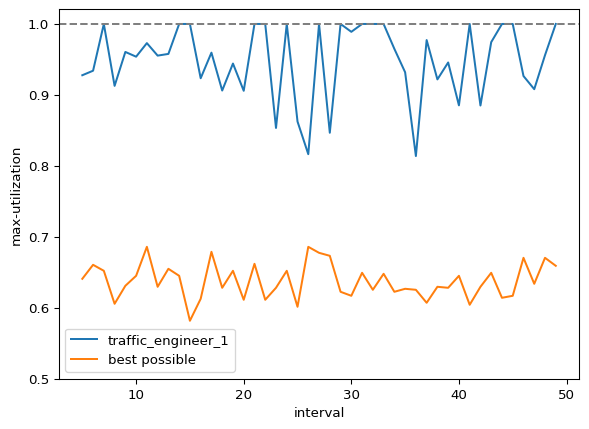

In [12]:
# @title Plot code { display-mode: "form" }
utilization, best_utilization = [], []
dropped = 0
for prediction, intervals in zip(predictions, windows[1:]):
  fractions = path_fractions(traffic_engineer_1(ell, C, prediction), prediction)
  for D in intervals:
    load = link_load(fractions, D)
    utilization.append(max_utilization(load, C))
    dropped += dropped_load(load, C)

    best_fractions = path_fractions(traffic_engineer_1(ell, C, D), D)
    best_utilization.append(max_utilization(link_load(best_fractions, D), C))
percent_dropped_1 = 100 * dropped / windows[1:].sum()

t = np.arange(window, num_intervals)
plt.plot(t, utilization, label="traffic_engineer_1")
plt.plot(t, best_utilization, label="best possible")
plt.axhline(1, color="gray", linestyle="--")
plt.ylim(bottom=0.5)
plt.xlabel("interval")
plt.ylabel("max-utilization")
plt.legend()
plt.show()

### Dealing with bursty traffic

The issue here is that $D$ is not perfect! It is only a prediction of
the load.

Consider the example below, where the A-B link increased from a
predicted demand $2$ to a real demand $4$. Then (a) has 100% link
utilization, while (b) stays at 75%.

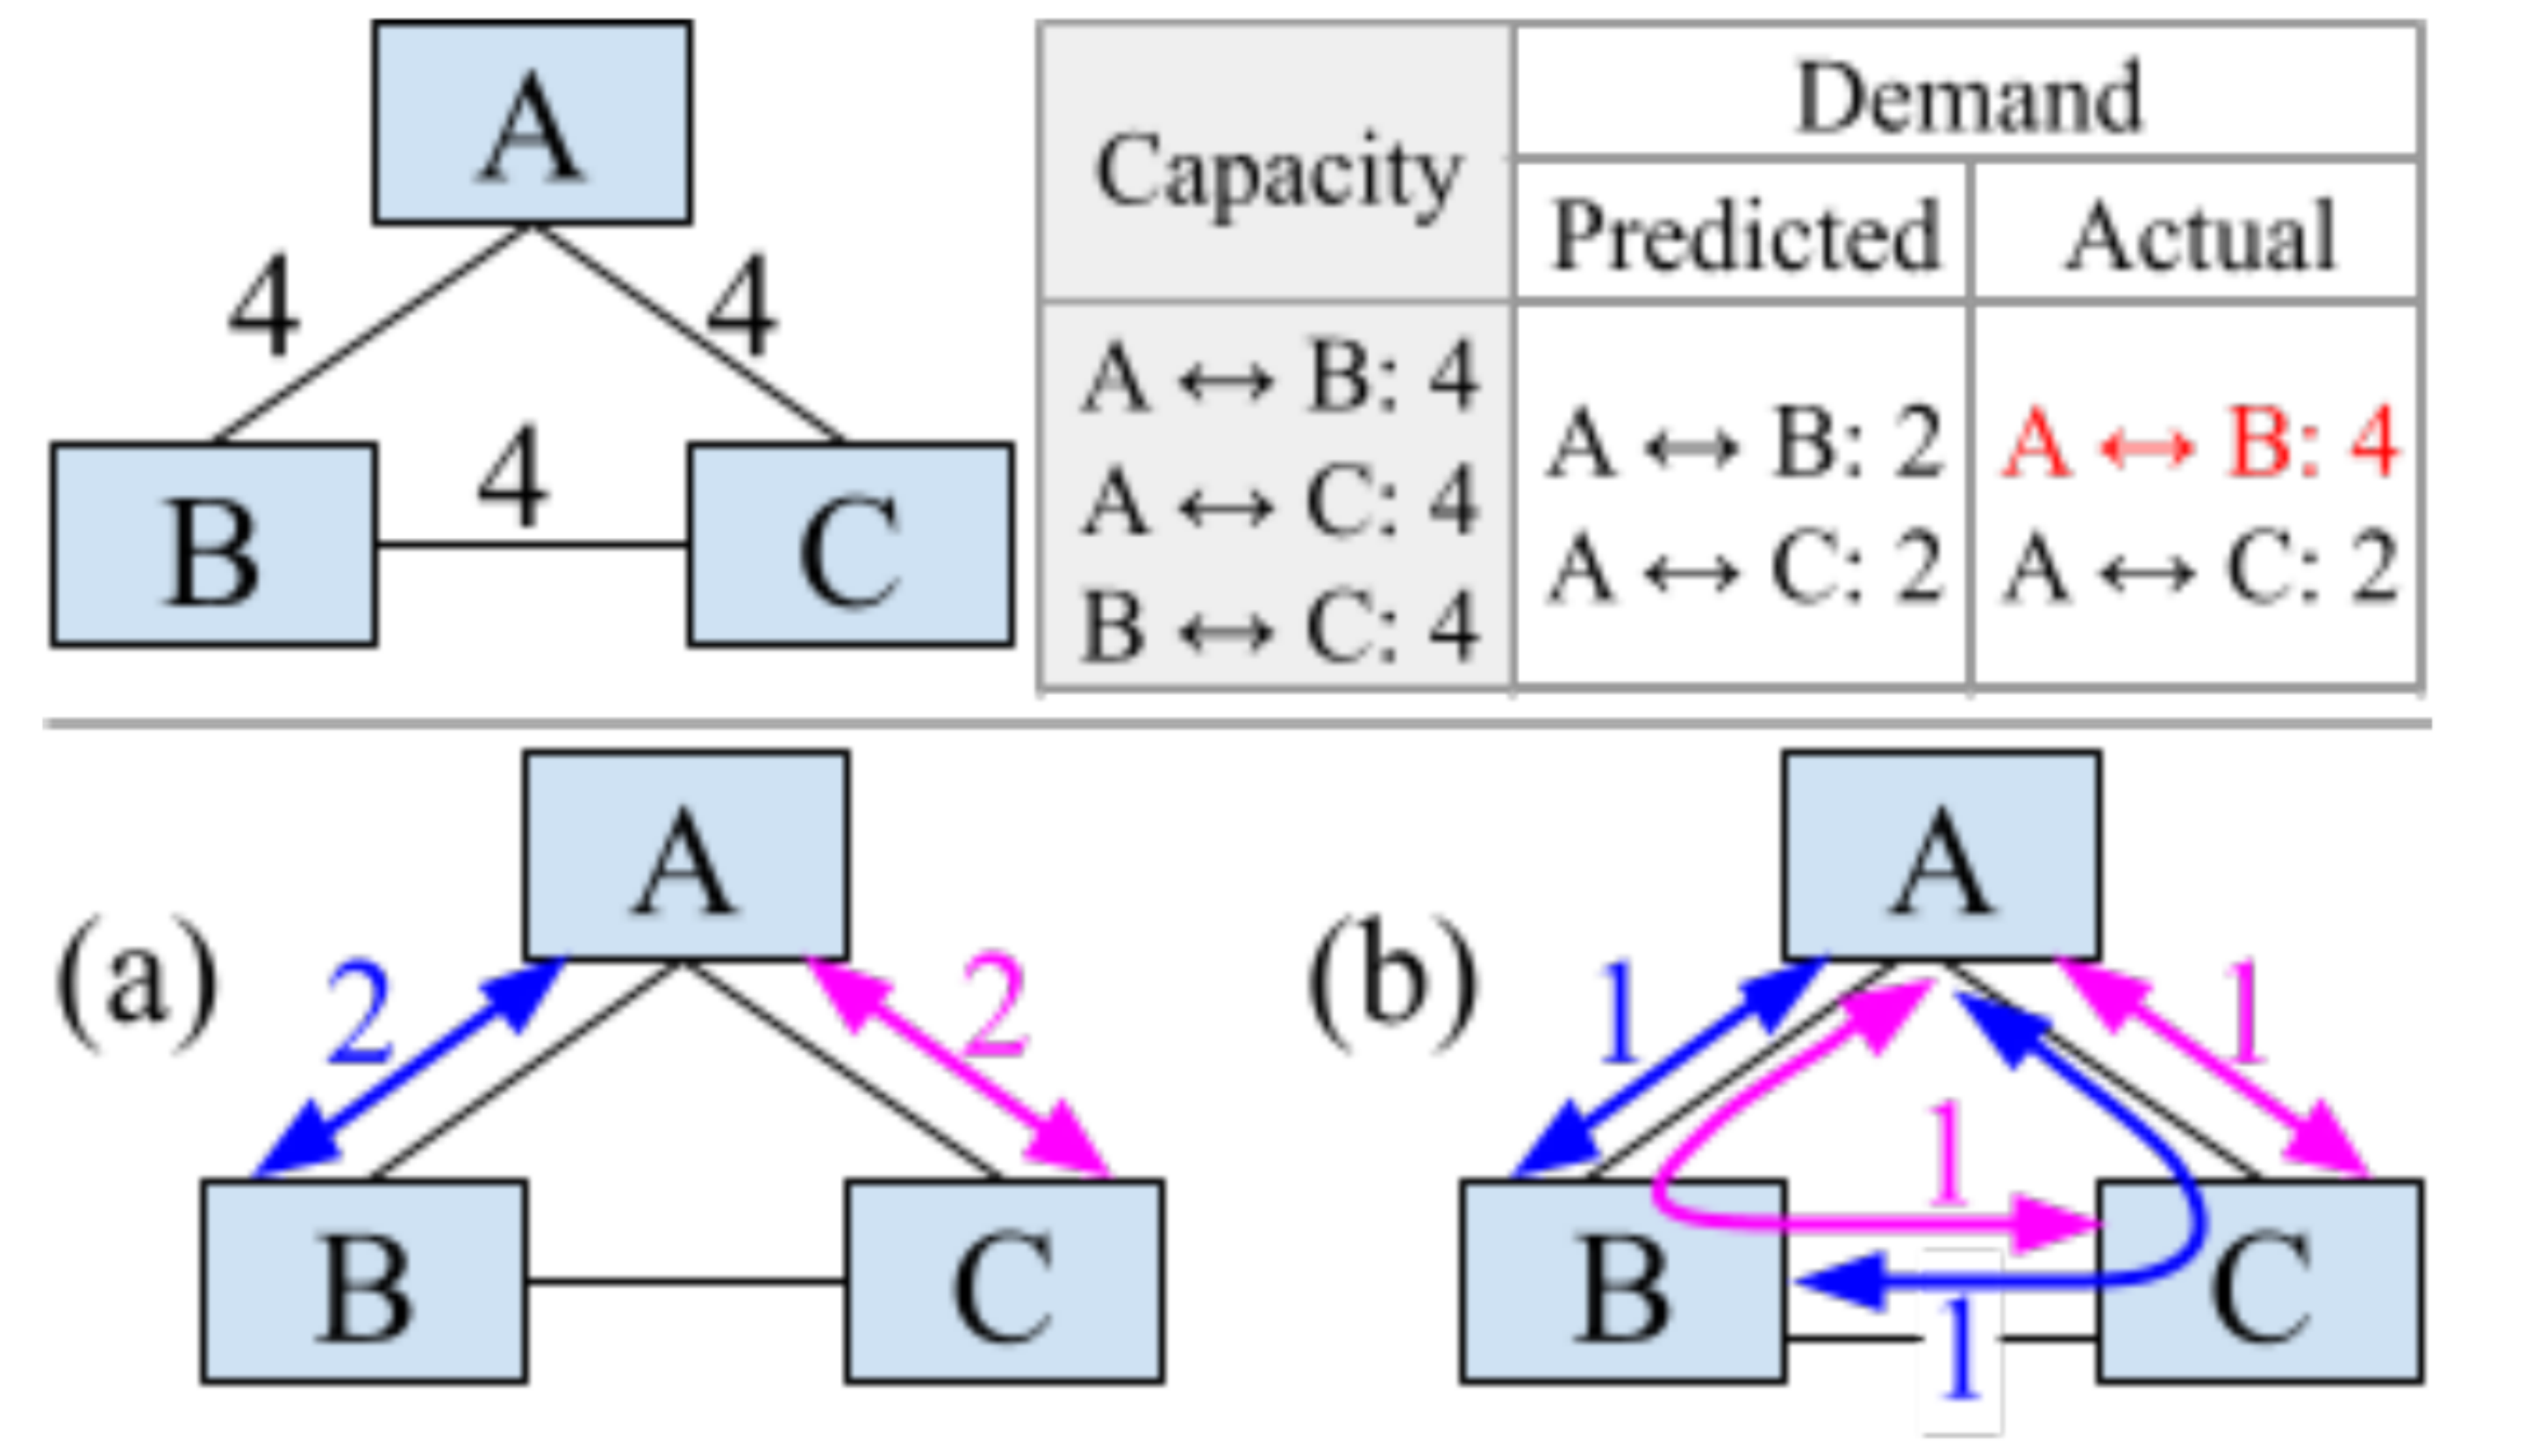

Google’s approach here is to introduce a spread parameter $S$. Splitting
commodities across multiple paths decreases the probability that
multiple bursts will occur over the same link, and thus preventing
bottlenecks.

In [13]:
def min_capacity(C: np.ndarray, p: path) -> float:
  """The smallest capacity of a link along p."""
  return min(C[u, v] for u, v in itertools.pairwise(p))

def traffic_engineer_2(ell: int, S: float, C: np.ndarray, D: np.ndarray) -> dict[path, float]:
  """
  As traffic_engineer_1, with the spread parameter S in (0, 1]:
  no path carries more than 1/S times its share of its commodity's demand,
  where the shares are proportional to each path's smallest link capacity.
  Returns the flow along every path.
  """
  paths = all_paths(ell)

  m = gp.Model("te2")
  m.Params.OutputFlag = 0
  x = {p: m.addVar() for p in paths}
  U = m.addVar()

  for i, j in itertools.permutations(range(ell), 2):
    P_ij = [p for p in paths if p[0] == i and p[-1] == j]
    m.addConstr(gp.quicksum(x[p] for p in P_ij) == D[i, j])

    total = sum(min_capacity(C, q) for q in P_ij)
    for p in P_ij:
      share = min_capacity(C, p) / total
      m.addConstr(x[p] <= D[i, j] * share / S)

  for u, v in itertools.permutations(range(ell), 2):
    through = [p for p in paths if (u, v) in itertools.pairwise(p)]
    m.addConstr(gp.quicksum(x[p] for p in through) <= U * C[u, v])

  m.setObjective(U, GRB.MINIMIZE)
  m.optimize()
  return {p: x[p].X for p in paths}

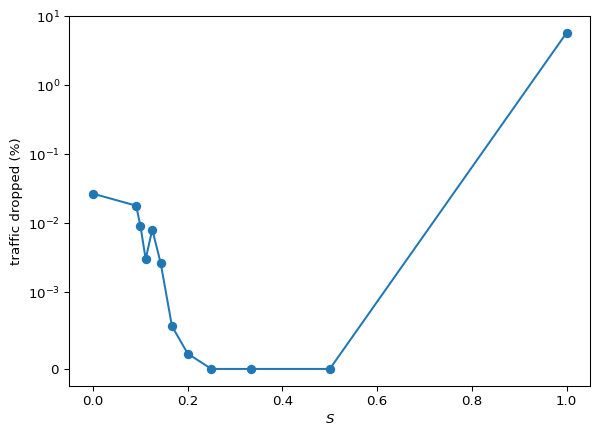

In [14]:
# @title Plot code { display-mode: "form" }
Ss = 1 / np.arange(ell - 1, 0, -1)
percent_dropped = []
for S in Ss:
  dropped = 0
  for prediction, intervals in zip(predictions, windows[1:]):
    fractions = path_fractions(traffic_engineer_2(ell, S, C, prediction), prediction)
    for D in intervals:
      dropped += dropped_load(link_load(fractions, D), C)
  percent_dropped.append(100 * dropped / windows[1:].sum())

plt.plot([0, *Ss], [percent_dropped_1, *percent_dropped], marker="o")
plt.xlabel("$S$")
plt.ylabel("traffic dropped (%)")
plt.yscale("symlog", linthresh=1e-3)
plt.show()

## Branch and Bound

Many problems, e.g. vertex cover as we will see later, require integer
decision variables. This is a much more powerful problem known as an
integer program. In this section, we will implement a solver by reducing
it to many cases of linear programs.

First, we will simplify it to only consider binary decision variables.
This is because in general, integer variables can be encoded in binary.

Then, the naive approach here is to DFS / recursively-backtrack down the
space of all binary assignments. Branch-and-bound is a technique that
whenever it finds a feasible solution, bounds the solution value. Then,
it checks if the branch is worth considering by whether the LP falls on
the side of the bound.

Hint: remember to check the status code of the model after optimizing!

In [15]:
def is_integral(value: float) -> bool:
  return abs(value - round(value)) < 1e-6

def enforce_value(var: gp.Var, val: float):
  var.LB = val
  var.UB = val

def branch_and_bound(
  m: gp.Model, x: list[gp.Var], L: float, U: float, best: list[float] | None
) -> tuple[float, list[float] | None]:
  """
  Given model m, relaxed variables x, L/U lower/upper bounds, and the incumbent solution best.
  Update U and best if this branch has a better integer solution.
  """
  if L >= U:
    return U, best

  m.optimize()
  if m.Status != GRB.OPTIMAL:
    return U, best

  z = m.ObjVal
  L = max(L, z)
  if L >= U:
    return U, best

  values = [v.X for v in x]
  fractional = [j for j, value in enumerate(values) if not is_integral(value)]
  if not fractional:
    return z, values

  j = fractional[0]
  lb, ub = x[j].LB, x[j].UB
  for value in (0, 1):
    enforce_value(x[j], value)
    U, best = branch_and_bound(m, x, L, U, best)
  x[j].LB, x[j].UB = lb, ub
  return U, best

def solve(m: gp.Model) -> tuple[float, list[float]] | None:
  """
  Minimize the integer program m via branch-and-bound.
  Returns optimal value U, and the optimal integer solution x,
  or None if m is infeasible.
  """
  m.update()
  x = [v for v in m.getVars() if v.VType == GRB.BINARY]
  for v in x:
    v.VType = GRB.CONTINUOUS
  m.Params.OutputFlag = 0
  U, best = branch_and_bound(m, x, float("-inf"), float("inf"), None)
  if best is None:
    return None
  return U, best

Now that we have a (presumably) working integer solver, let’s test it
out. We will find the minimum vertex cover for an undirected graph $G$.

In [16]:
def vertex_cover(G: nx.Graph) -> gp.Model:
  """The integer program for a minimum vertex cover of G."""
  m = gp.Model("vertex_cover")
  x = {v: m.addVar(vtype=GRB.BINARY) for v in G.nodes}
  for u, v in G.edges:
    m.addConstr(x[u] + x[v] >= 1)
  m.setObjective(gp.quicksum(x[v] for v in G.nodes), GRB.MINIMIZE)
  return m

Plotting it, we find a solution value of 6, which is optimal (exercise:
why).

In [17]:
# @title Graph code { display-mode: "form" }
n, p = 10, 0.3
G = nx.erdos_renyi_graph(n, p, seed=1)
pos = nx.spring_layout(G, seed=0)

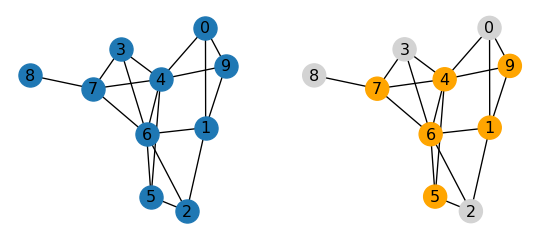

In [18]:
# @title Plot code { display-mode: "form" }
U, best = solve(vertex_cover(G))
cover = [v for v in G.nodes if round(best[v]) == 1]
colors = ["orange" if v in cover else "lightgray" for v in G.nodes]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
nx.draw(G, pos, ax=ax1, with_labels=True)
nx.draw(G, pos, ax=ax2, with_labels=True, node_color=colors)
plt.show()

## Traveling Salesman

### MTZ formulation

We tour the capitals of the 48 contiguous US states, using the data from
Gurobi’s [TSP
example](https://github.com/Gurobi/modeling-examples/tree/master/traveling_salesman).

> **Note**
>
> On the free Gurobi license, models are limited to 2000 variables and
> 2000 constraints. The models below have $n^2$ arc variables (plus $n$
> MTZ variables), so keep at most 44 states, e.g. with
> `states = states[:44]`.

In [19]:
# @title Capitals data { display-mode: "form" }
import json
import urllib.request

url = "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/traveling_salesman/capitals.json"
capitals = json.loads(urllib.request.urlopen(url).read())
states = [s for s in capitals if s not in ["AK", "HI"]]
coordinates = np.array([[float(capitals[s]["long"]), float(capitals[s]["lat"])] for s in states])

n = len(states)
V = range(n)              # cities 0,...,n-1
c = np.linalg.norm(coordinates[:, None] - coordinates[None, :], axis=2)

In [20]:
m = gp.Model("TSP_MTZ")
m.Params.OutputFlag = 0
x = m.addVars(V, V, vtype=gp.GRB.BINARY, name="x")
u = m.addVars(V, lb=1, ub=n, name="u")

# Objective
m.setObjective(gp.quicksum(c[i,j] * x[i,j] for i, j in itertools.permutations(V, 2)), gp.GRB.MINIMIZE)

# Degree constraints
for i in V:
  m.addConstr(gp.quicksum(x[i,j] for j in V if j != i) == 1)
  m.addConstr(gp.quicksum(x[j,i] for j in V if j != i) == 1)

# MTZ subtour elimination
for i in range(1, n):
  for j in range(1, n):
    if i != j: m.addConstr(u[j] >= u[i] + 1 - n * (1 - x[i,j]))

m.optimize()

### Lazy constraints

In [21]:
def find_subtours(n, xsol):
  """Given integer solution (all 0.0 or 1.0), return list of subtour node sets."""
  G = nx.DiGraph()
  G.add_nodes_from(range(n))

  for i in range(n):
    for j in range(n):
      if i != j and int(round(xsol[i, j]))==1:       # round 1.0 to 1 and 0.0 to 0
        G.add_edge(i, j)

  components = list(nx.strongly_connected_components(G))

  # A subtour is any component smaller than n
  return [S for S in components if len(S) < n]

In [22]:
def callback(model, where):
  if where == GRB.Callback.MIPSOL:
    x = model._x
    n = model._n

    # 1. Read the integer solution
    xsol = model.cbGetSolution(x)

    # 2. Find subtours
    subtours = find_subtours(n, xsol)

    # 3. For each subtour, add a lazy constraint
    for S in subtours:
      complement = set(range(n)) - S
      model.cbLazy(
        gp.quicksum(x[i,j] for i in S for j in complement) >= 1
      )

In [23]:
m = gp.Model("TSP_lazy_only")
m.Params.OutputFlag = 0
x = m.addVars(V, V, vtype=GRB.BINARY, name="x")
for i in V:
  x[i,i].ub = 0   # no self-loops

m.setObjective(
  gp.quicksum(c[i,j]*x[i,j] for i, j in itertools.permutations(V, 2)),
  GRB.MINIMIZE)

for i in V:
  m.addConstr(gp.quicksum(x[i,j] for j in V if j != i) == 1)
  m.addConstr(gp.quicksum(x[j,i] for j in V if j != i) == 1)

m.Params.LazyConstraints = 1   # REQUIRED: tells Gurobi to expect cbLazy

m._x = x    # attach variables so callback can access them
m._n = n
m.optimize(callback)

### Branch-and-cut

In [24]:
def mincut_separate_dfj(n, xstar):
  """
  Find the most violated DFJ constraint in a fractional solution.
  Returns (S, cut_value) if violated, else (None, None).
  """
  edges = [(i, j) for i in range(n) for j in range(n) if i != j]
  caps = [float(xstar[i, j]) for (i, j) in edges]

  g = ig.Graph(n=n, edges=edges, directed=True)
  g.es["cap"] = caps

  cut = g.mincut(capacity="cap")      # global directed min-cut
  val = float(cut.value)

  if val < 1 - 1e-6:    # tolerance for numerical safety
    A, B = cut.partition
    S = set(A) if 0 < len(A) < n else set(B)
    if 0 < len(S) < n:
      return S, val
  return None, None

In [25]:
def callback(model, where):
  x, n = model._x, model._n

  # (A) CORRECTNESS: reject integer solutions with subtours
  if where == GRB.Callback.MIPSOL:
    xsol = model.cbGetSolution(x)
    subtours = find_subtours(n, xsol)
    for S in subtours:
      complement = set(range(n)) - S
      model.cbLazy(
        gp.quicksum(x[i,j] for i in S for j in complement) >= 1)

  # (B) PERFORMANCE: tighten LP relaxation with DFJ cuts
  if where == GRB.Callback.MIPNODE:
    if model.cbGet(GRB.Callback.MIPNODE_STATUS) != GRB.OPTIMAL: return
    if model.cbGet(GRB.Callback.MIPNODE_NODCNT) != 0: return
    xstar = model.cbGetNodeRel(x)
    S, val = mincut_separate_dfj(n, xstar)
    if S is not None:
      comp = set(range(n)) - S
      model.cbCut(
        gp.quicksum(x[i,j] for i in S for j in comp) >= 1)

In [26]:
m2 = gp.Model("TSP_branch_and_cut")
m2.Params.OutputFlag = 0
x = m2.addVars(V, V, vtype=GRB.BINARY, name="x")
for i in V:
  x[i,i].ub = 0   # no self-loops

m2.setObjective(
  gp.quicksum(c[i,j]*x[i,j] for i, j in itertools.permutations(V, 2)),
  GRB.MINIMIZE)

for i in V:
  m2.addConstr(gp.quicksum(x[i,j] for j in V if j != i) == 1)
  m2.addConstr(gp.quicksum(x[j,i] for j in V if j != i) == 1)

m2.Params.LazyConstraints = 1   # required for cbLazy
m2._x = x
m2._n = n
m2.optimize(callback)